In [1]:
!pip install wordcloud


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

df = pd.read_csv("cyberbullying_tweets.csv")
print(df.shape)
print(df.cyberbullying_type.value_counts())

(47692, 2)
cyberbullying_type
religion               7998
age                    7992
gender                 7973
ethnicity              7961
not_cyberbullying      7945
other_cyberbullying    7823
Name: count, dtype: int64


In [3]:
# exact duplicate texts
print("Duplicate texts:", df.tweet_text.duplicated().sum())

# same text, DIFFERENT labels  (label noise)
n_labels = df.groupby("tweet_text").cyberbullying_type.nunique()
conflict = n_labels[n_labels > 1]
print("Texts with conflicting labels:", len(conflict))

# which label pairs conflict most?
pairs = (df[df.tweet_text.isin(conflict.index)]
         .groupby("tweet_text").cyberbullying_type
         .agg(lambda s: " + ".join(sorted(set(s)))))
print(pairs.value_counts())

#few examples
pd.set_option("display.max_colwidth", 120)
print(pairs.sample(5, random_state=1))

# clean version: dropping exact duplicates, then texts that carry conflicting labels
df = df.drop_duplicates()
df = df.drop_duplicates("tweet_text", keep=False)
print("Rows kept for analysis:", len(df))

Duplicate texts: 1675
Texts with conflicting labels: 1639
cyberbullying_type
not_cyberbullying + other_cyberbullying    1456
gender + other_cyberbullying                124
gender + not_cyberbullying                   50
ethnicity + religion                          4
ethnicity + not_cyberbullying                 2
ethnicity + gender                            1
gender + religion                             1
not_cyberbullying + religion                  1
Name: count, dtype: int64
tweet_text
lol at angry men writing me essays through Facebook messenger that amount to "be nicer when you're being harassed"                  not_cyberbullying + other_cyberbullying
the theme for their instant restaurant appears to be "barbie's dream narcissism kitchen" 💋 #MKR                                                gender + other_cyberbullying
@Craig_Alford I got him one of those, but it didn't seem to hold him tight enough.                                                  not_cyberbullying + other_

In [4]:
EXTRA_STOP = {"rt","amp","im","dont","didnt","isnt","like","just","get","got",
              "people","one","would","know","think","say","make","go"}  # only for FREQUENCY clouds
STOP = set(ENGLISH_STOP_WORDS) | EXTRA_STOP

def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)   # links
    t = re.sub(r"@\w+", " ", t)             # mentions
    t = re.sub(r"[^a-z\s]", " ", t)         # numbers, punctuation, emoji
    return " ".join(w for w in t.split() if len(w) > 2)

df["clean"] = df.tweet_text.map(clean)
classes = sorted(df.cyberbullying_type.unique())
df[["tweet_text","clean","cyberbullying_type"]].sample(5, random_state=2)

,tweet_text,clean,cyberbullying_type
40116,"Are u on drugs? Never has there been a retaliation on colored people after such an attack, why try to force this to ...",are drugs never has there been retaliation colored people after such attack why try force this racism issue,ethnicity
16161,Hmm...dnt beleive ur stupid media.. muslims are enjoying all rights in india unlike how u Pakistanis treat ur minori...,hmm dnt beleive stupid media muslims are enjoying all rights india unlike how pakistanis treat minorities denying th...,religion
40153,"Fuck you for this dawg lmfaoooo ""@CoonGawd: Dumb worthless chinks if your eyes weren't so fucking tight you'd see th...",fuck you for this dawg lmfaoooo dumb worthless chinks your eyes weren fucking tight you see the fucking orange nigger,ethnicity
45089,Maybe not. Those women certainly didn’t tell the whole truth and nothing but the truth. I also noticed most of them ...,maybe not those women certainly didn tell the whole truth and nothing but the truth also noticed most them were old ...,ethnicity
31464,"RT @tauriqmoosa: ""Today's industry"" https://t.co/lvoI0GzbBZ",today industry,other_cyberbullying


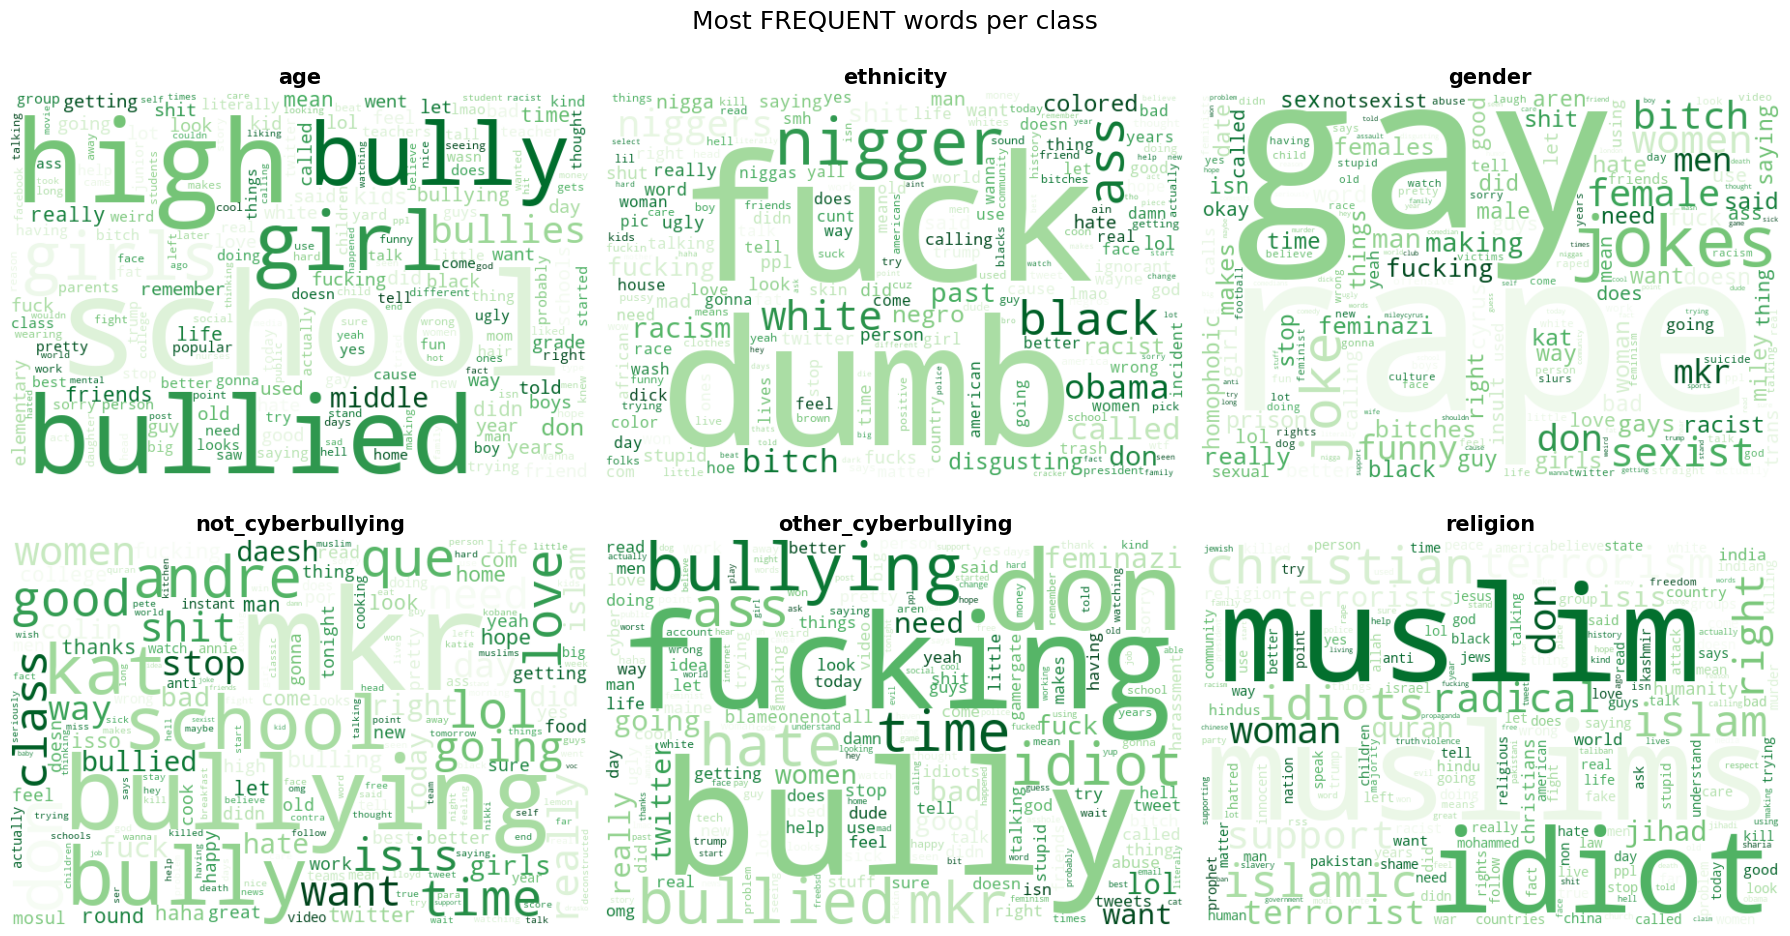

In [8]:
from collections import Counter

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, k in zip(axes.ravel(), classes):
    words = " ".join(df[df.cyberbullying_type == k].clean).split()
    freq = Counter(w for w in words if w not in STOP)
    wc = WordCloud(width=600, height=400, background_color="white",
                   colormap="Greens").generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(k, fontsize=15, fontweight="bold")
plt.suptitle("Most FREQUENT words per class", fontsize=18)
plt.tight_layout(); plt.show()

In [10]:
# binary=True means: we only count "does this tweet contain the word?" (yes/no)
cv = CountVectorizer(binary=True, min_df=40)   # ignore very rare words
X = cv.fit_transform(df.clean)
vocab = np.array(cv.get_feature_names_out())

total = np.asarray(X.sum(axis=0)).ravel()      # number of tweets containing each word
S = pd.DataFrame(index=vocab)
S["n_tweets"] = total
for k in classes:
    in_class = np.asarray(X[(df.cyberbullying_type == k).values].sum(axis=0)).ravel()
    S[k] = in_class / total                    # share of this word's tweets that are in class k

S.sort_values("n_tweets", ascending=False).head(15).round(2)

,n_tweets,age,ethnicity,gender,not_cyberbullying,other_cyberbullying,religion
the,18918,0.25,0.18,0.15,0.09,0.08,0.25
and,14999,0.27,0.15,0.18,0.08,0.06,0.26
you,12819,0.14,0.24,0.13,0.07,0.08,0.33
that,10069,0.25,0.18,0.17,0.07,0.10,0.24
school,7873,0.93,0.01,0.01,0.04,0.00,0.00
are,7268,0.17,0.15,0.18,0.07,0.07,0.36
for,7102,0.28,0.14,0.15,0.08,0.09,0.25
not,6144,0.15,0.14,0.27,0.07,0.09,0.28
but,5719,0.23,0.14,0.29,0.05,0.08,0.21
this,5567,0.23,0.20,0.13,0.08,0.13,0.23


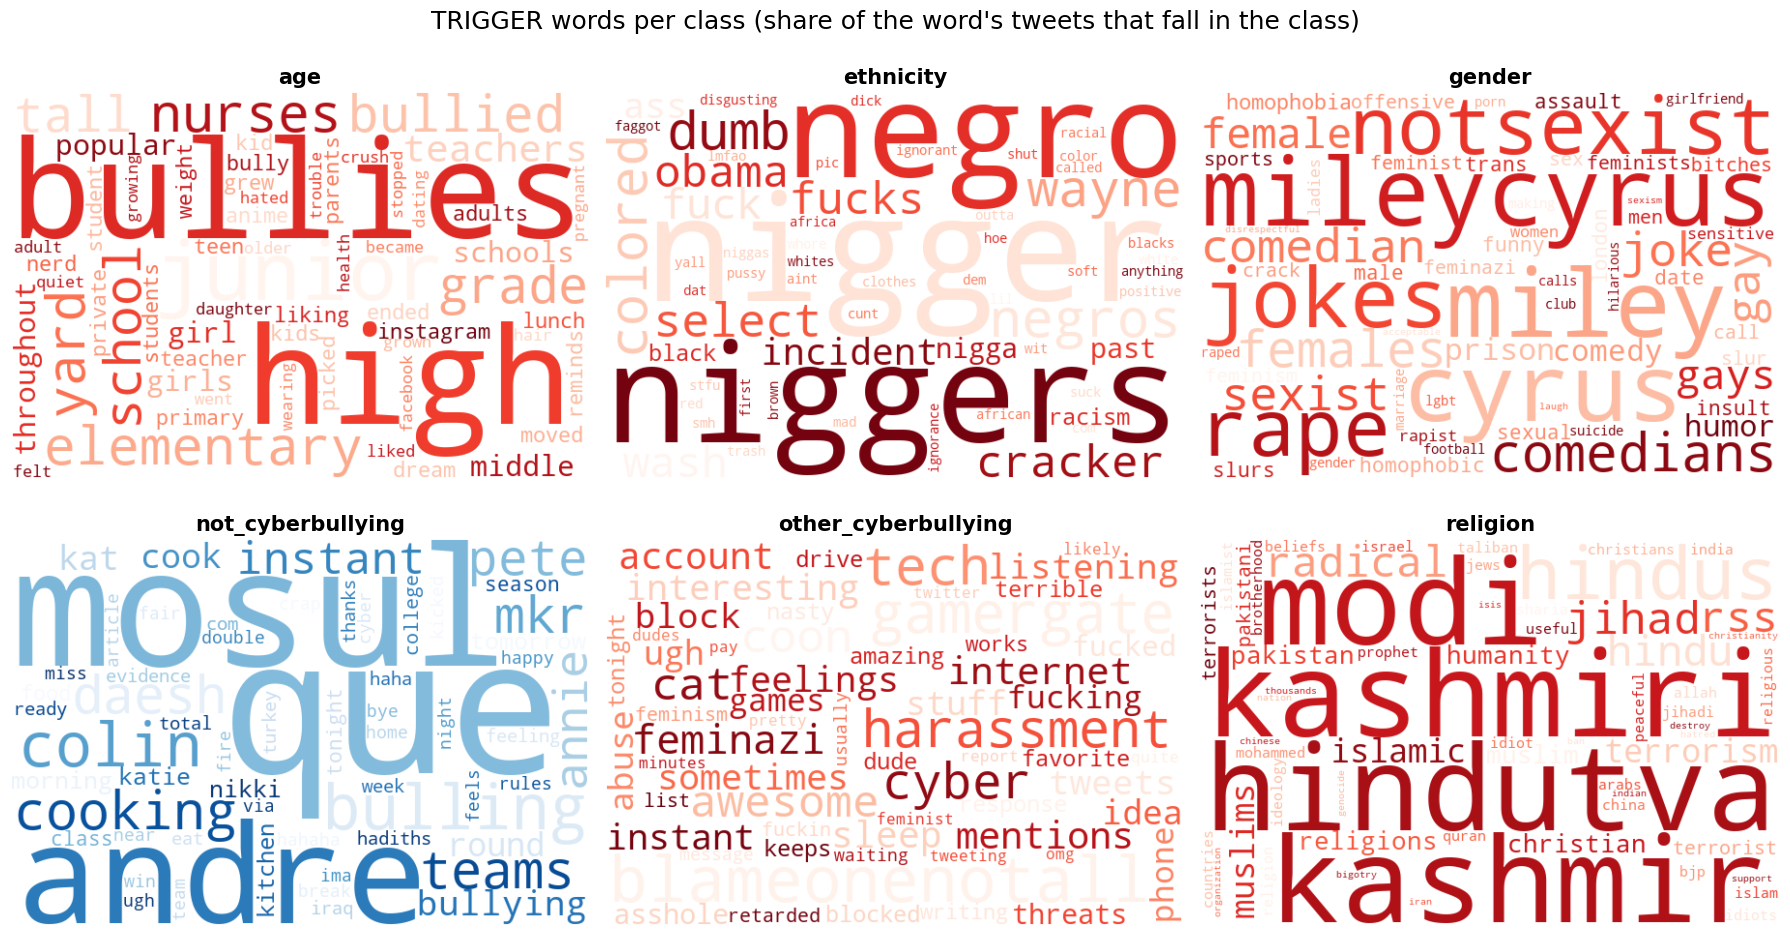

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, k in zip(axes.ravel(), classes):
    t = S[S.n_tweets >= 60][k].sort_values(ascending=False).head(60)
    wc = WordCloud(width=600, height=400, background_color="white",
                   colormap="Blues" if k == "not_cyberbullying" else "Reds"
                   ).generate_from_frequencies((t * 100).to_dict())
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(k, fontsize=15, fontweight="bold")
plt.suptitle("TRIGGER words per class (share of the word's tweets that fall in the class)", fontsize=18)
plt.tight_layout(); plt.show()

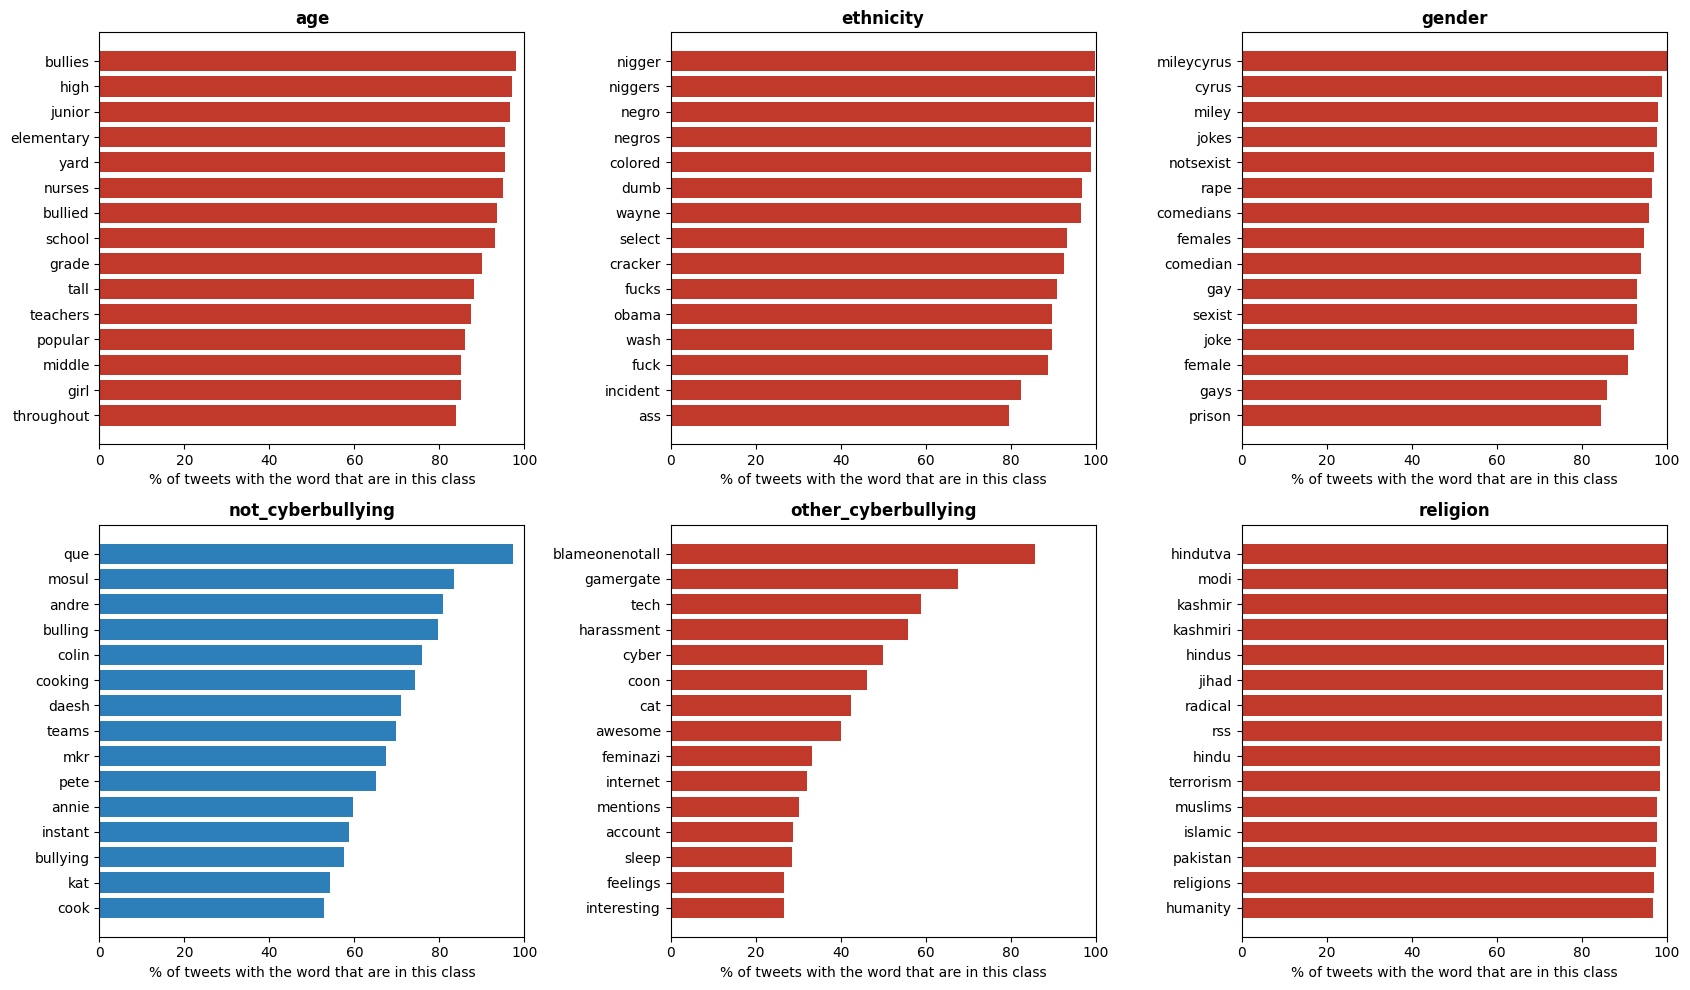

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, k in zip(axes.ravel(), classes):
    t = S[S.n_tweets >= 60].sort_values(k, ascending=False).head(15).iloc[::-1]
    ax.barh(t.index, t[k] * 100, color="#2c7fb8" if k == "not_cyberbullying" else "#c0392b")
    ax.set_xlim(0, 100); ax.set_title(k, fontweight="bold")
    ax.set_xlabel("% of tweets with the word that are in this class")
plt.tight_layout(); plt.show()

In [13]:
def lookup(word):
    if word not in S.index:
        print(word, "-> not in vocab (too rare)"); return
    r = S.loc[word]
    print(f"'{word}' appears in {int(r.n_tweets)} tweets:")
    print((r[classes] * 100).round(1).sort_values(ascending=False).to_string(), "\n")

for w in ["school", "muslim", "rape", "gay", "dumb", "fuck", "idiot", "bullied", "lol", "mkr"]:
    lookup(w)

'school' appears in 7873 tweets:
age                    93.1
not_cyberbullying       4.3
ethnicity               1.1
gender                  0.8
other_cyberbullying     0.4
religion                0.3 

'muslim' appears in 2189 tweets:
religion               96.4
not_cyberbullying       1.5
gender                  0.9
age                     0.5
ethnicity               0.5
other_cyberbullying     0.1 

'rape' appears in 4128 tweets:
gender                 96.4
religion                2.2
other_cyberbullying     0.5
age                     0.3
ethnicity               0.3
not_cyberbullying       0.3 

'gay' appears in 3882 tweets:
gender                 93.0
age                     3.9
religion                1.3
ethnicity               1.2
not_cyberbullying       0.5
other_cyberbullying     0.1 

'dumb' appears in 5094 tweets:
ethnicity              96.7
age                     1.0
gender                  1.0
religion                0.7
not_cyberbullying       0.3
other_cyberbullying   

In [14]:
# Words that are strongly tied to a class but have NOTHING to do with that class's topic.
# Look through these yourself and write down which ones look like data-collection artifacts.
for k in classes:
    t = S[S.n_tweets >= 60][k].sort_values(ascending=False).head(40)
    print(f"\n=== {k} ===")
    print(", ".join(t.index))


=== age ===
bullies, high, junior, elementary, yard, nurses, bullied, school, grade, tall, teachers, popular, middle, girl, throughout, girls, schools, instagram, primary, moved, nerd, liking, lunch, teacher, adults, bully, dream, parents, teen, ended, students, kids, grew, picked, weight, anime, reminds, private, student, kid

=== ethnicity ===
nigger, niggers, negro, negros, colored, dumb, wayne, select, cracker, fucks, obama, wash, fuck, incident, ass, nigga, past, racism, black, disgusting, cunt, pic, hoe, white, soft, ignorant, mad, african, smh, wit, com, color, positive, clothes, stfu, anything, shut, pussy, brown, aint

=== gender ===
mileycyrus, cyrus, miley, jokes, notsexist, rape, comedians, females, comedian, gay, sexist, joke, female, gays, prison, comedy, humor, homophobia, homophobic, insult, slurs, date, trans, assault, male, sexual, london, funny, feminists, feminazi, offensive, feminism, crack, bitches, feminist, sex, sports, call, slur, men

=== not_cyberbullying ==

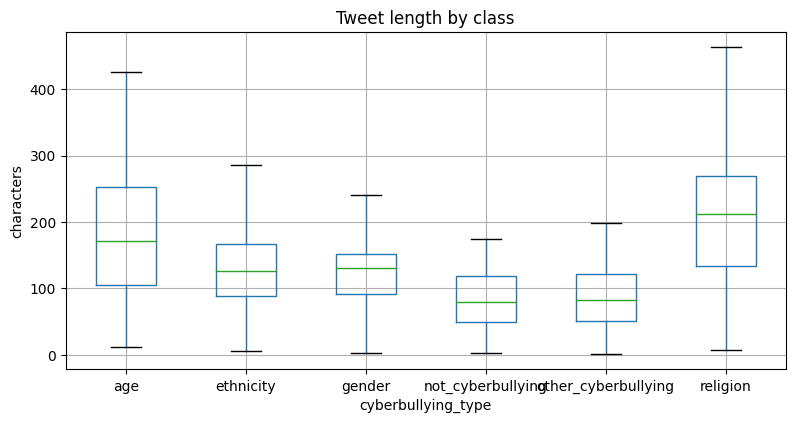

Accuracy using length ONLY: 0.305 (random guessing = 0.167)


In [15]:
df["length"] = df.tweet_text.str.len()
df.boxplot("length", by="cyberbullying_type", figsize=(9, 4.5), showfliers=False)
plt.suptitle(""); plt.title("Tweet length by class"); plt.ylabel("characters"); plt.show()

# can a model using ONLY length (no words!) beat random guessing (1/6 = 0.167)?
acc = cross_val_score(DecisionTreeClassifier(max_depth=4), df[["length"]],
                      df.cyberbullying_type, cv=5).mean()
print("Accuracy using length ONLY:", round(acc, 3), "(random guessing = 0.167)")

In [16]:
# ============ CELL 10: do victims' stories sit in the 'age' class? ============
# read these yourself: are they bullying, or people talking ABOUT being bullied?
pd.set_option("display.max_colwidth", 200)
print(df[(df.cyberbullying_type == "age") & df.clean.str.contains("bullied")]
        .tweet_text.sample(8, random_state=5).to_string())

37334                                                                                                                           she looks like the kind of girl that would've bullied me in high school tbh lmao
36936                 Logged onto Facebook for the first time in 2 years. The first thing I saw was a girl that bullied me in high school preaching girls supporting girls. Time to log off for a few more years
33239    Most of my friends that were girls just stopped talking to me irl. Cause I’m boring lol. I didn’t get along with girls in high school because I got bullied by most of them. So I just kept to mysel...
34669                            in high school i was not regularly called a f*g in the hallway so that y’all could act like anybody was for real bullied for dressing like an e boy/girl before it was cool smh
32869                                                                                                                   if it ain’t a 5 incher and a girl who was pr